<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Описание" data-toc-modified-id="Описание-1"><span class="toc-item-num">1&nbsp;&nbsp;</span><strong>Описание</strong></a></span></li><li><span><a href="#Импорт-библиотек-и-данных" data-toc-modified-id="Импорт-библиотек-и-данных-2"><span class="toc-item-num">2&nbsp;&nbsp;</span><strong>Импорт библиотек и данных</strong></a></span></li><li><span><a href="#EDA-и-преодобработка-данных" data-toc-modified-id="EDA-и-преодобработка-данных-3"><span class="toc-item-num">3&nbsp;&nbsp;</span><strong>EDA и преодобработка данных</strong></a></span></li><li><span><a href="#Классификация-текста-с-Google-Gemma-2" data-toc-modified-id="Классификация-текста-с-Google-Gemma-2-4"><span class="toc-item-num">4&nbsp;&nbsp;</span><strong>Классификация текста с <a href="https://huggingface.co/google/gemma-2-2b-it" target="_blank">Google Gemma-2</a></strong></a></span><ul class="toc-item"><li><span><a href="#Загрузка-токенизатора-и-модели" data-toc-modified-id="Загрузка-токенизатора-и-модели-4.1"><span class="toc-item-num">4.1&nbsp;&nbsp;</span>Загрузка токенизатора и модели</a></span></li><li><span><a href="#Настройка-параметров-обучения" data-toc-modified-id="Настройка-параметров-обучения-4.2"><span class="toc-item-num">4.2&nbsp;&nbsp;</span>Настройка параметров обучения</a></span></li><li><span><a href="#Дообучение-LoRA-Gemma-2" data-toc-modified-id="Дообучение-LoRA-Gemma-2-4.3"><span class="toc-item-num">4.3&nbsp;&nbsp;</span>Дообучение LoRA Gemma-2</a></span></li><li><span><a href="#Подбор-оптимального-порога" data-toc-modified-id="Подбор-оптимального-порога-4.4"><span class="toc-item-num">4.4&nbsp;&nbsp;</span>Подбор оптимального порога</a></span></li><li><span><a href="#Анализ-ошибок-модели-на-валидации" data-toc-modified-id="Анализ-ошибок-модели-на-валидации-4.5"><span class="toc-item-num">4.5&nbsp;&nbsp;</span>Анализ ошибок модели на валидации</a></span></li><li><span><a href="#Инференс-на-тестовой-выборке" data-toc-modified-id="Инференс-на-тестовой-выборке-4.6"><span class="toc-item-num">4.6&nbsp;&nbsp;</span>Инференс на тестовой выборке</a></span></li></ul></li><li><span><a href="#Результаты" data-toc-modified-id="Результаты-5"><span class="toc-item-num">5&nbsp;&nbsp;</span><strong>Результаты</strong></a></span></li></ul></div>

# **Обработка естественного языка с использованием твитов о катастрофах**

##  **Описание**

Конкурс на [**Kaggle**](https://www.kaggle.com/competitions/nlp-getting-started/overview "Перейти на страницу конкурса")


***Х*** (ранее *Twitter*) стал важным каналом связи во время чрезвычайных ситуаций. Повсеместное распространение смартфонов позволяет людям сообщать о происходящих чрезвычайных ситуациях в режиме реального времени. В связи с этим все больше организаций, таких как организации по оказанию помощи при стихийных бедствиях и новостные агентства, заинтересованы в программном мониторинге.

Однако не всегда ясно, действительно ли слова пользователя описывают катастрофу или он выражается метафорически.

Необходимо создать модель машинного обучения, которая будет предсказывать, касается ли данный твит реальной катастрофы или нет. Если да, то метка **`1`**. Если нет, то метка **`0`**.

**Описание набора данных:**

Обучающий и тестовый наборы содержат следующую информацию:

- `id`- уникальный идентификатор для каждого твита
- `text` - сам твит
- `keyword` - ключевое слово из этого твита (может быть пустым)
- `location` - адрес отправителя твита (может также быть пустым)
- **`target`** - только в обучающей выборке. Указывает, посвящен ли твит реальной катастрофе (1) или нет (0).

**Метрика качества модели:**

**F1-мера** для сравнения прогнозируемых и ожидаемых ответов.

## **Импорт библиотек и данных**

In [1]:
!pip install -q huggingface_hub ydata-profiling unsloth[colab-new]==2026.10.7
!unsloth install-kernels xformers

Unsloth: installed xformers (xformers-0.0.35-py39-none-manylinux_2_28_x86_64.whl).


In [2]:
import os
import warnings
warnings.simplefilter(action='ignore')

import numpy as np
import pandas as pd
pd.set_option('display.max_colwidth', 1000)
from ydata_profiling import ProfileReport

from google.colab import userdata
from google.colab import files

import matplotlib.pyplot as plt
%config InlineBackend.figure_format='svg'

import torch
from datasets import Dataset
from unsloth import FastLanguageModel
from transformers import (
    set_seed,
    EarlyStoppingCallback,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE=0
set_seed(RANDOM_STATE)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [3]:
data_dir = '.'
required_files = ['train.csv', 'test.csv', 'sample_submission.csv']

files_exist = all(
    os.path.exists(os.path.join(data_dir, f)) for f in required_files
)

if not files_exist:
    token = userdata.get('KAGGLE_API_TOKEN')

    !mkdir -p ~/.kaggle
    !echo '{token}' > ~/.kaggle/access_token
    !chmod 600 ~/.kaggle/access_token

    !kaggle competitions download -c nlp-getting-started
    !unzip -q *.zip -d {data_dir}
    !rm -f *.zip

data, test_data, sample_submission = [
    pd.read_csv(os.path.join(data_dir, f"{name}.csv"))
    for name in ['train', 'test', 'sample_submission']
]

## **EDA и преодобработка данных**

[**Интерактивный сравнительный EDA**](https://natashanoskova.github.io/ai_experiments/text_classification/02_disaster_tweets/) **обучающего и тестового сетов** выполнен с помощью YData Profiling.

```
train_report = ProfileReport(data,
                             title="Disaster Tweets Training Set EDA",
                             explorative=True
                            )
test_report = ProfileReport(test_data,
                            title="Disaster Tweets Test Set EDA",
                            explorative=True
                           )
comparison_report = train_report.compare(test_report)      
comparison_report.to_file("train_test_comparison.html")
```

**Основные наблюдения и выводы:**

|      | Обучающая выборка | Тестовая выборка |
| :--- | :---: | :---: |
| пропуски в `keyword` | 0.8% | 0.8% |
| пропуски в `location` | 33.3% | 33.9% |
| баланс классов 0 / 1 | 57% / 43% |  |

- Пропуски в колонках заполняем значением "*unknown*".
- С учетом суммарной длины текста самого комментария, ключевого слова и адреса пользователя, целесообразно установить ограничение `max_seq_length=256` токенов.
- Для корректной работы трейнера, создадим отсутствующую колонку `target` в тестовой выборке с *нулевыми значениями*.

In [4]:
# Проверим, как выглядит образец для сабмиссии
sample_submission.head()

,id,target
0,0,0
1,2,0
2,3,0
3,9,0
4,11,0


In [5]:
# Заполняем все пропуски в обеих выборках
data.fillna('unknown', inplace=True)

test_data.fillna('unknown', inplace=True)

In [6]:
# Создаем колонку целевого признака с нулевыми значениями
test_data['target'] = 0

In [7]:
# Создаем валидационную выборку, фиксируем random_state для воспроизводимости

train_data, val_data = train_test_split(
    data, test_size=1200, random_state=RANDOM_STATE, stratify=data["target"]
)

print('Размер обучающей выборки :', train_data.shape)
print('\nБаланс классов в обучающей выборке :')
display(train_data.target.value_counts(normalize=1))
print("\nРазмер валидационной выборки :", val_data.shape)
print("\nБаланс классов в валидационной выборке :")
display(val_data.target.value_counts(normalize=1))

Размер обучающей выборки : (6413, 5)

Баланс классов в обучающей выборке :


,proportion
target,
0,0.570404
1,0.429596



Размер валидационной выборки : (1200, 5)

Баланс классов в валидационной выборке :


,proportion
target,
0,0.57
1,0.43


## **Классификация текста с [Google Gemma-2](https://huggingface.co/google/gemma-2-2b-it)**

Для решения поставленной задачи бинарной классификации токсичных комментариев используем уже знакомую **Gemma-2-2B-It** в режиме классификатора.

### Загрузка токенизатора и модели

Загружаем базовую модель **google/gemma-2-2b-it** с 4-битным квантованием **QLoRA**. Это позволит запустить дообучение на видеокарте Tesla T4.

In [8]:
# Максимальная длина последовательности на основании EDA
max_seq_length = 256

In [9]:
# Загружаем предобученную модель и токенизатор через Unsloth

model_cls, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "google/gemma-2-2b-it",
    max_seq_length = max_seq_length,
    load_in_4bit = True,
    num_labels = 2
)

==((====))==  Unsloth 2026.10.7: Fast Gemma2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Not planning a device map; the load builds Gemma2ForSequenceClassification, not the planned Gemma2ForCausalLM. Using `sequential`.


Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

Gemma2ForSequenceClassification LOAD REPORT from: unsloth/gemma-2-2b-it-bnb-4bit
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Unsloth: Will load unsloth/gemma-2-2b-it-bnb-4bit as a legacy tokenizer.


In [10]:
# Настраиваем pad_token
tokenizer.pad_token = tokenizer.eos_token

# Настройка для стабильности эмбеддингов в 4-бит
model_cls.config.pad_token_id = tokenizer.pad_token_id

**Преобразование данных и динамический паддинг:**

- Объединяем тексты колонок `keyword`, `location` и `text` в каждой строке.
- Переводим данные из формата Pandas DataFrame в формат `Hugging Face Dataset`.
- Колонку целевого признака `toxic` переименовываем в `labels`.
- На этапе токенизации отключаем паддинг внутри функции, переносим эту задачу на уровень сборщика батчей.

In [11]:
def unite_columns(row):
    kw = row['keyword']
    loc = row['location']
    text = row['text']
    return f"Keyword: {kw} | Location: {loc} | Text: {text}"

train_data['text_united'] = train_data.apply(unite_columns, axis=1)
val_data['text_united'] = val_data.apply(unite_columns, axis=1)
test_data['text_united'] = test_data.apply(unite_columns, axis=1)

In [12]:
#Выводим пример полученных данных
train_data.head()

,id,keyword,location,text,target,text_united
2736,3933,devastated,unknown,abcnews - Obama Declares Disaster for Typhoon-Devastated Saipan: Obama signs disaster declaration for Northern... http://t.co/mg5eAJElul,1,Keyword: devastated | Location: unknown | Text: abcnews - Obama Declares Disaster for Typhoon-Devastated Saipan: Obama signs disaster declaration for Northern... http://t.co/mg5eAJElul
6792,9731,tragedy,unknown,Rly tragedy in MP: Some live to recount horror: ÛÏWhen I saw coaches of my train plunging into water I called ... http://t.co/vScPGMsJXY,1,Keyword: tragedy | Location: unknown | Text: Rly tragedy in MP: Some live to recount horror: ÛÏWhen I saw coaches of my train plunging into water I called ... http://t.co/vScPGMsJXY
1245,1796,buildings%20on%20fire,Sweden,shootings explosions hand grenades thrown at cars and houses &amp; vehicles and buildings set on fire. It all just baffles me.Is this Sweden?,1,Keyword: buildings%20on%20fire | Location: Sweden | Text: shootings explosions hand grenades thrown at cars and houses &amp; vehicles and buildings set on fire. It all just baffles me.Is this Sweden?
6402,9149,suicide%20bomber,Helsinki,Islamic State claims suicide bombing at Saudi Arabian mosque: Ten members of emergency service... http://t.co/mpOaEFQl6k via @josephjett,1,Keyword: suicide%20bomber | Location: Helsinki | Text: Islamic State claims suicide bombing at Saudi Arabian mosque: Ten members of emergency service... http://t.co/mpOaEFQl6k via @josephjett
2480,3557,desolate,NYC area,RT @danielkemp6 Likened to THE 39 STEPS and The GOOD SHEPHERD by the FILM producer THE DESOLATE GARDEN on ALL here http://t.co/fel4QhWyFD,0,Keyword: desolate | Location: NYC area | Text: RT @danielkemp6 Likened to THE 39 STEPS and The GOOD SHEPHERD by the FILM producer THE DESOLATE GARDEN on ALL here http://t.co/fel4QhWyFD


In [13]:
train_ds = Dataset.from_pandas(
    train_data[['text_united', 'target']].rename(columns={'target': 'labels'}).reset_index(drop=True)
)

val_ds = Dataset.from_pandas(
    val_data[['text_united', 'target']].rename(columns={'target': 'labels'}).reset_index(drop=True)
)

test_ds = Dataset.from_pandas(
    test_data[['text_united', 'target']].rename(columns={'target': 'labels'}).reset_index(drop=True)
)

def tokenize_function(examples):
    return tokenizer(examples["text_united"], truncation=True, max_length=max_seq_length, padding=False)

train_ds_tknz = train_ds.map(tokenize_function, batched=True)
val_ds_tknz = val_ds.map(tokenize_function, batched=True)
test_ds_tknz = test_ds.map(tokenize_function, batched=True)

Map:   0%|          | 0/6413 [00:00<?, ? examples/s]

Map:   0%|          | 0/1200 [00:00<?, ? examples/s]

Map:   0%|          | 0/3263 [00:00<?, ? examples/s]

### Настройка параметров обучения

- Критерий выбора модели **Macro F1** -  среднее арифметическое обоих классов. Обычный F1-score по умолчанию для класса 1 может маскировать то, что модель начала хуже угадывать класс 0.
- Модель обучается на стандартной функции потерь Cross-Entropy Loss, которая заложена в Gemma2ForSequenceClassification.
- Каждые 50 шагов Trainer приостанавливает обучение и считает Macro F1 на валидационной выборке.
- Параметры `metric_for_best_model="eval_macro_f1"` и `greater_is_better=True` заставляют Trainer сохранять и в конце вернуть модель, которая набрала максимальный Macro F1.

In [14]:
# Настройка адаптера через Unsloth

model_cls = FastLanguageModel.get_peft_model(
    model_cls,
    r = 32,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_alpha = 64,
    lora_dropout = 0,
    bias = "none"
)

Unsloth 2026.10.7 patched 26 layers with 26 QKV layers, 26 O layers and 26 MLP layers.


In [15]:
training_args_cls = TrainingArguments(
    output_dir="./gemma_2_classification",
    per_device_train_batch_size=16,
    gradient_accumulation_steps=2,
    learning_rate=8e-5,
    lr_scheduler_type="cosine",
    warmup_steps=100,
    max_steps=1000,
    optim="paged_adamw_8bit",
    fp16=True,
    bf16=False,
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",    # Отслеживаем Macro F1, чтобы защитить модель от дисбаланса
    greater_is_better=True
)

In [16]:
# Создаем сборщик батчей, который автоматически сделает паддинг

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [17]:
# Считаем макро-F1 - среднее между F1 для класса 0 и класса 1
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    macro_f1 = f1_score(labels, predictions, average='macro')

    return {"macro_f1": macro_f1}

In [18]:
trainer_cls = Trainer(
    model=model_cls,
    args=training_args_cls,
    train_dataset=train_ds_tknz,
    eval_dataset=val_ds_tknz,
    compute_metrics=compute_metrics,
    data_collator=data_collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

### Дообучение LoRA Gemma-2

In [19]:
print("Запускаем обучение Gemma-2 через Unsloth...\n")

trainer_cls.train()

print("ОБУЧЕНИЕ ЗАВЕРШЕНО ✅")

Запускаем обучение Gemma-2 через Unsloth...



==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 6,413 | Num Epochs = 5 | Total steps = 1,000
O^O/ \_/ \    Batch size per device = 16 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (16 x 2 x 1) = 32
 "-____-"     Trainable parameters = 41,538,048 of 2,655,884,544 (1.56% trained)
Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma2ForSequenceClassification's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


Step,Training Loss,Validation Loss,Macro F1
50,0.661158,0.511955,0.760475
100,0.412299,0.437751,0.815522
150,0.631385,0.445515,0.790259
200,0.440952,0.453647,0.808691
250,0.345119,0.447374,0.829754
300,0.412992,0.438146,0.827431
350,0.334557,0.447004,0.801196
400,0.435705,0.426211,0.826873


Unsloth: Restored added_tokens_decoder metadata in ./gemma_2_classification/checkpoint-50/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in ./gemma_2_classification/checkpoint-50.
Unsloth: Restored added_tokens_decoder metadata in ./gemma_2_classification/checkpoint-100/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in ./gemma_2_classification/checkpoint-100.
Unsloth: Restored added_tokens_decoder metadata in ./gemma_2_classification/checkpoint-150/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in ./gemma_2_classification/checkpoint-150.
Unsloth: Restored added_tokens_decoder metadata in ./gemma_2_classification/checkpoint-200/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in ./gemma_2_classification/checkpoint-200.
Unsloth: Restored added_tokens_decoder metadata in ./gemma_2_classification/checkpoint-250/tokenizer_config.json.
Unsloth: Preserved sentencep

ОБУЧЕНИЕ ЗАВЕРШЕНО ✔


In [20]:
history = trainer_cls.state.log_history

train_loss_data = [log for log in history if "loss" in log]
df_loss = pd.DataFrame(train_loss_data)

eval_data = [log for log in history if "eval_loss" in log and "eval_macro_f1" in log]
df_eval = pd.DataFrame(eval_data)

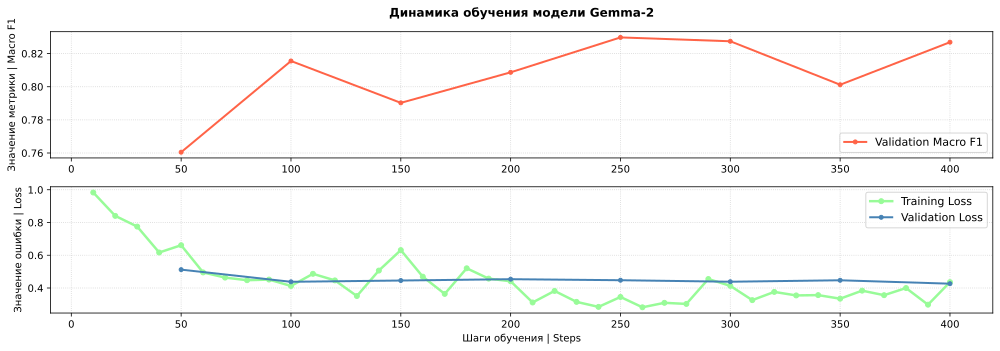

In [21]:
# Строим график изменения ошибки и Macro F1

plt.figure(figsize=(14, 5))

plt.subplot(2, 1, 1)

plt.plot(df_eval['step'], df_eval['eval_macro_f1'], label='Validation Macro F1',
         color='tomato', linewidth=2, marker='o', markersize=4)
plt.title('Динамика обучения модели Gemma-2', fontsize=12, pad=15, fontweight='bold')
plt.ylabel('Значение метрики | Macro F1', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='lower right')


plt.subplot(2, 1, 2, sharex=plt.gca())

plt.plot(df_loss['step'], df_loss['loss'], label='Training Loss',
         color='palegreen', linewidth=2.5, marker='o', markersize=5)

plt.plot(df_eval['step'], df_eval['eval_loss'], label='Validation Loss',
         color='steelblue', linewidth=2, marker='o', markersize=4)
plt.xlabel('Шаги обучения | Steps', fontsize=10)
plt.ylabel('Значение ошибки | Loss', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

- После **250-го** шага модель начала переобучаться, подстраиваться под частые классы, из-за чего Macro F1 упал до 0.8012.
- На шаге 300 и 350 Validation Loss колеблется, а Macro F1 падает, что является признаком переобучения.
- На шаге 400 Validation Loss упал до 0.4262, но Macro F1 равен 0.8269, что хуже, чем на шаге 250.

### Подбор оптимального порога

In [22]:
# Переводим логиты модели в вероятности от 0 до 1 с помощью функции Softmax

def softmax(x):
    e_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return e_x / e_x.sum(axis=-1, keepdims=True)

In [23]:
# Получаем предсказания модели на валидационной выборке

val_predictions = trainer_cls.predict(val_ds_tknz)

# Получаем матрицу вероятностей, где второй столбец — вероятность токсичности
val_probabilities = softmax(val_predictions.predictions)
val_probs = val_probabilities[:, 1]

# Перебираем разные пороги от 0.1 до 0.9
print("Ищем оптимальный порог:")

best_f1 = 0
best_threshold = 0.1
thresholds = np.arange(0.1, 0.91, 0.01)

for threshold in thresholds:
    # если вероятность выше порога — ставим 1, иначе 0
    temp_preds = (val_probs >= threshold).astype(int)
    current_f1 = f1_score(val_data['target'], temp_preds)
    print(f"Порог: {threshold:.2f} | Итоговый F1-score: {current_f1:.4f}")

    if current_f1 > best_f1:
        best_f1 = current_f1
        best_threshold = threshold

print(f"\nСамый высокий F1 = {best_f1:.4f} достигается при пороге {best_threshold:.2f}")

Ищем оптимальный порог:
Порог: 0.10 | Итоговый F1-score: 0.7396
Порог: 0.11 | Итоговый F1-score: 0.7496
Порог: 0.12 | Итоговый F1-score: 0.7541
Порог: 0.13 | Итоговый F1-score: 0.7546
Порог: 0.14 | Итоговый F1-score: 0.7624
Порог: 0.15 | Итоговый F1-score: 0.7658
Порог: 0.16 | Итоговый F1-score: 0.7720
Порог: 0.17 | Итоговый F1-score: 0.7735
Порог: 0.18 | Итоговый F1-score: 0.7774
Порог: 0.19 | Итоговый F1-score: 0.7831
Порог: 0.20 | Итоговый F1-score: 0.7845
Порог: 0.21 | Итоговый F1-score: 0.7865
Порог: 0.22 | Итоговый F1-score: 0.7854
Порог: 0.23 | Итоговый F1-score: 0.7896
Порог: 0.24 | Итоговый F1-score: 0.7910
Порог: 0.25 | Итоговый F1-score: 0.7946
Порог: 0.26 | Итоговый F1-score: 0.7957
Порог: 0.27 | Итоговый F1-score: 0.7967
Порог: 0.28 | Итоговый F1-score: 0.7978
Порог: 0.29 | Итоговый F1-score: 0.7996
Порог: 0.30 | Итоговый F1-score: 0.8000
Порог: 0.31 | Итоговый F1-score: 0.7989
Порог: 0.32 | Итоговый F1-score: 0.7974
Порог: 0.33 | Итоговый F1-score: 0.7970
Порог: 0.34 | Ит

In [24]:
# Применяем оптимальный порог
val_preds = (val_probs >= best_threshold).astype(int)

# Получаем валидационный лосс напрямую из метрик
val_loss = val_predictions.metrics['test_loss']
val_data['gemma_preds'] = val_preds

# Выводим отчет для лучшего порога
print(f"\n Средний Loss на валидационной выборке : {val_loss:.4f}")
print(f"\n📊 Метрики на валидационной выборке при лучшем пороге {best_threshold:.2f} :\n")
print(classification_report(val_data['target'], val_preds, target_names=['Clean (0)', 'Toxic (1)']))


 Средний Loss на валидационной выборке : 0.4474

📊 Метрики на валидационной выборке при лучшем пороге 0.56 :

              precision    recall  f1-score   support

   Clean (0)       0.85      0.88      0.86       684
   Toxic (1)       0.83      0.79      0.81       516

    accuracy                           0.84      1200
   macro avg       0.84      0.84      0.84      1200
weighted avg       0.84      0.84      0.84      1200



### Анализ ошибок модели на валидации

In [25]:
# FN

false_negatives = val_data.query('target == 1 and gemma_preds == 0')

print(f"Найдено расхождений : {len(false_negatives)} из {len(val_data)}")
false_negatives[['text_united', 'target', 'gemma_preds']].head()

Найдено расхождений : 106 из 1200


,text_united,target,gemma_preds
3787,Keyword: fire%20truck | Location: unknown | Text: @KapoKekito on northgate by the taco truck that's fire.,1,0
5011,"Keyword: mudslide | Location: Ealing, London | Text: 'It looks like a mudslide!' And #GBBO is back with a belter!",1,0
6542,"Keyword: survived | Location: Washington, USA | Text: @rjkrraj @KarnakaranK @vimvith whether pressure or not NON wud not survived even if thalapathi didn't release",1,0
7144,Keyword: volcano | Location: Massachusetts | Text: Not only does he know the latest research the kiddo's GI specialist sang the volcano number from Inside Out. Now THAT is whole person care.,1,0
2624,Keyword: destruction | Location: unknown | Text: #Putin decree results in destruction of 10 tons of imported cheese near Russia-Ukraine border. RT @Independent http://t.co/K3pnNktlXh,1,0


In [26]:
# FP

false_positives = val_data.query('target == 0 and gemma_preds == 1')

print(f"Найдено расхождений : {len(false_positives)} из {len(val_data)}")
false_positives[['text_united', 'target', 'gemma_preds']].head()

Найдено расхождений : 84 из 1200


,text_united,target,gemma_preds
3311,Keyword: evacuate | Location: unknown | Text: The summer program I worked for went the city pool we had to evacuate because one of my kids left a surprise. @jimmyfallon #WorstSummerJob,0,1
1115,"Keyword: bombed | Location: Light and dark, form and void | Text: @KurtSchlichter @FALPhil This liberal compassion is BS. A specific Feminist said the US bombed Japan back to traditional sexist values.",0,1
6769,Keyword: tornado | Location: khartoum sudan | Text: A tornado flew around my room before you came,0,1
5147,"Keyword: nuclear%20reactor | Location: Fort Calhoun, NE | Text: Aug. 5: The Fort Calhoun Nuclear Station is at 100% capacity today according to the NRC: http://t.co/pztbQImpuW",0,1
4697,Keyword: landslide | Location: Edinburgh | Text: @CrowtherJohn @Effiedeans you just keep ur head in the sand john. The best place for it. Lbr after 97 landslide. Couldnt imagine situ now,0,1


**Качество данных:**

Обзор большего числа расхождений в ответах модели и исходной разметки показал, что в данных достаточно большое колчество явно ошибочной разметки.

### Инференс на тестовой выборке

In [27]:
# Получаем предсказания модели на тестовой выборке

test_predictions = trainer_cls.predict(test_ds_tknz)

test_probabilities = softmax(test_predictions.predictions)
test_probs = test_probabilities[:, 1]

# Применяем оптимальный порог
test_preds = (test_probs >= best_threshold).astype(int)

In [28]:
# Сохраняем предсказания для сабмисии на Kaggle
test_data['target'] = test_preds

submission = test_data[['id', 'target']]

submission.to_csv('submission.csv', index=False)
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Результаты**

Обученная модель показала хороший результат на тестовой выборке **F1 = 0,84339**.

[![img](https://raw.githubusercontent.com/natashanoskova/ai_experiments/refs/heads/main/text_classification/02_disaster_tweets/kaggle_lb.jpg)](https://www.kaggle.com/competitions/nlp-getting-started/leaderboard?search=Natasha+Noskova)

Возможные дальнейшие действия для улучшения метрики качества:
- использование обученной модели на исходных данных для удаления данных с явно ошибочной исходной разметкой.